# Task 3: Data augmentation study

**Objective:** increase validation accuracy (if possible) with data augmentation, and report
how each augmentation parameter affects validation accuracy.

Adam Oakes

**Setup**
* Same CNN as the Task 2 best model (5 conv blocks, 32→512 filters, GAP, sigmoid).
* Same optimizer (Adam), batch size (64), epochs (4) and early-stopping rule as Task 2.
* Every configuration trains a **fresh model from the same random seed**, so the only thing
  that changes between rows of the results table is the augmentation.
* The baseline (no augmentation) is trained twice with two different seeds. The gap between
  those two runs is the **noise floor**: a change smaller than that gap may be luck, not a real effect.

**About "image generators":** `ImageDataGenerator` is deprecated and was removed in Keras 3.
The replacements are Keras preprocessing layers (`RandomFlip`, `RandomRotation`, `RandomZoom`, ...).
They do the same job, and each row of the table lists the matching `ImageDataGenerator` argument.

**Pipeline note:** the CIFAKE images are 32×32. The previous notebooks had
`image_dataset_from_directory` upsample them to 180×180 on the CPU, and the earlier augmented run
applied the augmentation in `dataset.map` to those 180×180 tensors. That is why each epoch took
about 1400 s instead of about 40 s. Here the images load at their native 32×32 and are cached in
memory. Augmentation and the 32→180 bilinear upsample both happen **inside the model**, so they
run on the GPU. Augmentation layers are only active while training, so validation images go
through exactly the same path as in Task 2.

# Library imports and configuration

In [23]:
import os, json, time
from pathlib import Path

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("default")   # white background + dark text, regardless of the notebook theme

TASK = "task_3"
DATA_DIR = Path(os.environ.get("DATA_DIR", "../data"))
# EPOCHS = int(os.environ.get("EPOCHS", 4))          # same as Task 2
EPOCHS = 20
BATCH_SIZE = 64
NATIVE_SIZE = (32, 32)    # CIFAKE images are 32x32
MODEL_SIZE = (180, 180)   # same input size the Task 2 architecture was designed for
SEED = 42
SECOND_SEED = 7           # second baseline run -> noise floor

OUT = Path(os.environ.get("OUT_DIR", ".."))
plots = OUT / "plots" / TASK
results_dir = OUT / "results" / TASK
for d in (plots, results_dir):
    d.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = results_dir / "augmentation_results.csv"
HISTORY_JSON = results_dir / "augmentation_histories.json"
print("results ->", RESULTS_CSV.resolve())

results -> /home/adam/projects/Real_vs_Fake_Classifier/results/task_3/augmentation_results.csv


# Load the data (native 32×32, cached in memory)

In [24]:
def load(split, shuffle):
    return image_dataset_from_directory(
        DATA_DIR / split, image_size=NATIVE_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED,
    )

train_dataset = load("train", shuffle=True)
validation_dataset = load("validation", shuffle=False)
class_names = train_dataset.class_names
print(class_names)

# ~1 GB of RAM for 80k 32x32 float images; avoids decoding 80k JPEGs every epoch.
# The training set is reshuffled every epoch after the cache.
train_ds = (train_dataset.unbatch().cache()
            .shuffle(20_000, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = validation_dataset.cache().prefetch(tf.data.AUTOTUNE)

Found 80000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
['FAKE', 'REAL']


# Augmentation configurations

Each transform is first tested **by itself**, at several strengths, so its effect can be
isolated. Two combinations come after that:
* the "book" pipeline from the course notebook (flip + rotation 0.1 + zoom 0.2), and
* an automatically built **best-of** pipeline that combines the strongest setting from every
  transform family that beat the baseline.

Keras factors are fractions, not degrees. For example, `RandomRotation(0.1)` rotates by up to
±0.1·360° = ±36°, and `RandomTranslation(0.1, 0.1)` shifts by up to ±10% of the height and width.

In [25]:
# name -> (family, list of layer factories, ImageDataGenerator equivalent)
CONFIGS = {
    "baseline":            ("none",        [], "-"),
    f"baseline_seed{SECOND_SEED}": ("none", [], "- (noise-floor rerun)"),

    "flip_h":              ("flip",        [lambda: layers.RandomFlip("horizontal")], "horizontal_flip=True"),
    "flip_hv":             ("flip",        [lambda: layers.RandomFlip("horizontal_and_vertical")], "horizontal_flip=True, vertical_flip=True"),

    "rot_0.05":            ("rotation",    [lambda: layers.RandomRotation(0.05)], "rotation_range=18"),
    "rot_0.10":            ("rotation",    [lambda: layers.RandomRotation(0.10)], "rotation_range=36"),
    "rot_0.20":            ("rotation",    [lambda: layers.RandomRotation(0.20)], "rotation_range=72"),

    "zoom_0.1":            ("zoom",        [lambda: layers.RandomZoom(0.1)], "zoom_range=0.1"),
    "zoom_0.2":            ("zoom",        [lambda: layers.RandomZoom(0.2)], "zoom_range=0.2"),
    "zoom_0.3":            ("zoom",        [lambda: layers.RandomZoom(0.3)], "zoom_range=0.3"),

    "shift_0.1":           ("translation", [lambda: layers.RandomTranslation(0.1, 0.1)], "width_shift_range=0.1, height_shift_range=0.1"),
    "shift_0.2":           ("translation", [lambda: layers.RandomTranslation(0.2, 0.2)], "width_shift_range=0.2, height_shift_range=0.2"),

    "brightness_0.2":      ("brightness",  [lambda: layers.RandomBrightness(0.2, value_range=(0, 255))], "brightness_range=[0.8, 1.2]"),
    "contrast_0.2":        ("contrast",    [lambda: layers.RandomContrast(0.2)], "- (no direct equivalent)"),
    # Keras 3 requires GaussianNoise stddev in [0, 1], so scale to [0, 1], add noise (0.02 ~ 5/255), scale back
    "noise_0.02":          ("noise",       [lambda: layers.Rescaling(1 / 255),
                                            lambda: layers.GaussianNoise(0.02),
                                            lambda: layers.Rescaling(255)], "- (no direct equivalent)"),

    "book_combo":          ("combo",       [lambda: layers.RandomFlip("horizontal"),
                                            lambda: layers.RandomRotation(0.1),
                                            lambda: layers.RandomZoom(0.2)],
                            "horizontal_flip=True, rotation_range=36, zoom_range=0.2"),
}
print(len(CONFIGS), "configurations (+1 auto best-of combo)")

16 configurations (+1 auto best-of combo)


## What each augmentation does to an image

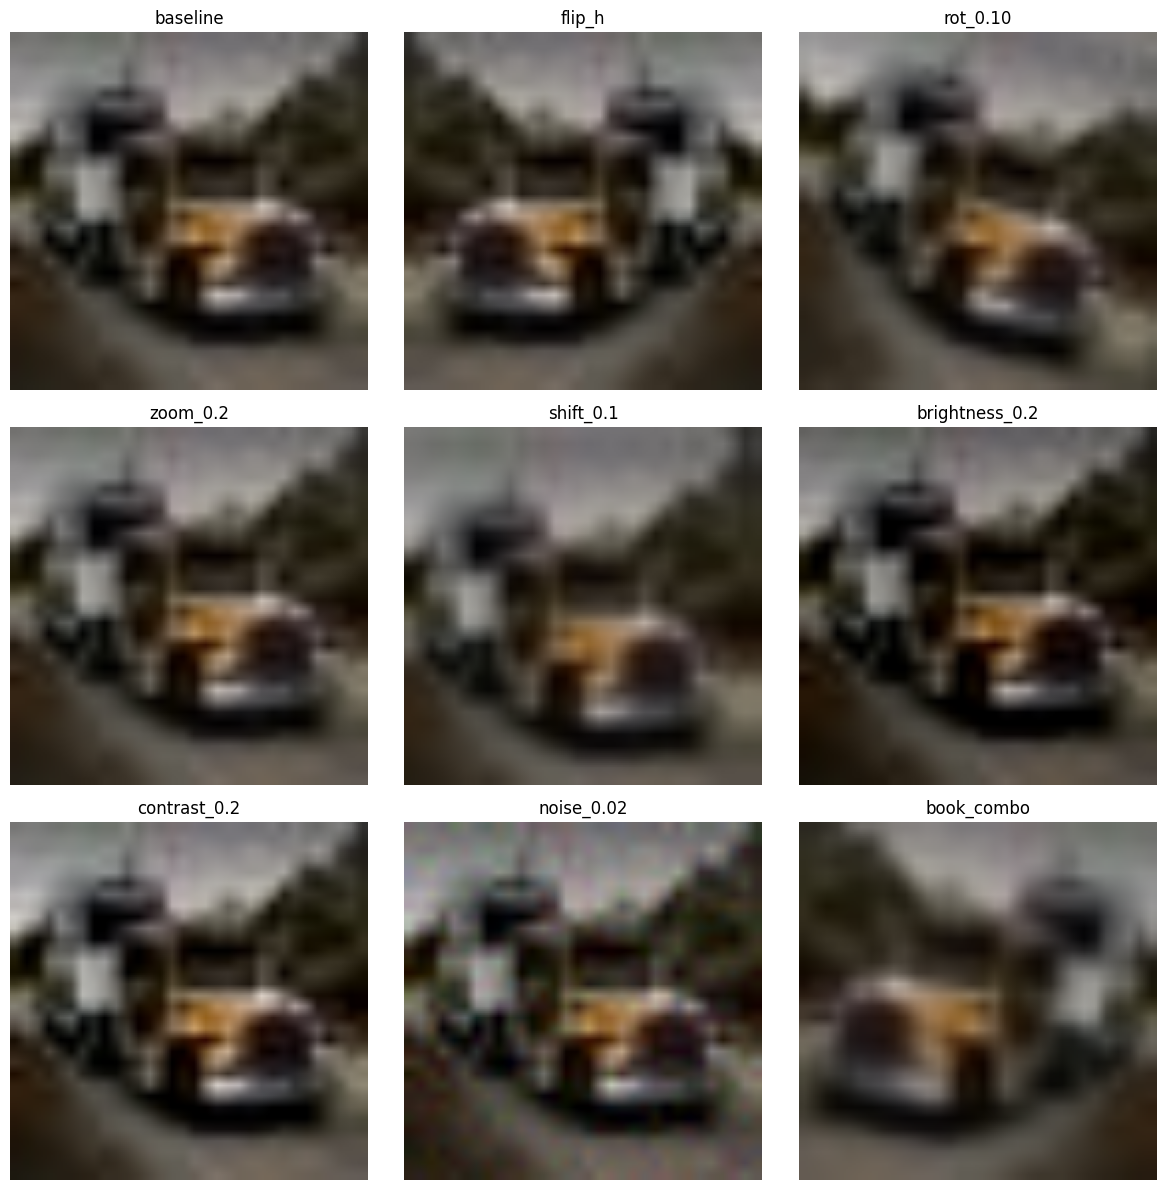

In [26]:
sample = next(iter(validation_dataset.take(1)))[0][:1]   # one image, native 32x32
upsample = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")
show = ["baseline", "flip_h", "rot_0.10", "zoom_0.2", "shift_0.1",
        "brightness_0.2", "contrast_0.2", "noise_0.02", "book_combo"]
plt.figure(figsize=(12, 12))
for i, name in enumerate(show):
    aug = keras.Sequential([f() for f in CONFIGS[name][1]])
    img = aug(sample, training=True) if CONFIGS[name][1] else sample
    img = keras.ops.convert_to_numpy(upsample(img))[0]
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(img, 0, 255).astype("uint8"))
    plt.title(name); plt.axis("off")
plt.tight_layout()
plt.savefig(plots / "augmentation_examples.png", dpi=120)
plt.show()

# Model: the Task 2 architecture with an augmentation stage at the front

In [27]:
def build_model(aug_factories, name):
    inputs = keras.Input(shape=NATIVE_SIZE + (3,))
    x = inputs
    for make in aug_factories:            # training-only; identity at inference
        x = make()(x)
    x = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")(x)   # same 32->180 upsample as Task 2
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(256, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(512, 3, activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name=name.replace(".", "p"))
    model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

build_model(CONFIGS["book_combo"][1], "preview").summary()

Model: "preview"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_42 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_11 (RandomFlip)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_12              │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_12 (RandomZoom)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_21 (Resizing)          │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_26 (Rescaling)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_90 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_91 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_92 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_74 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_93 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_75 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_94 (Conv2D)              │ (None, 7, 7, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_18     │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,569,089 (5.99 MB)

 Trainable params: 1,569,089 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

# Run the sweep

The results go to a CSV **after every configuration**. If the kernel dies or you stop it,
re-running this cell skips the configurations that already finished. To start over, delete
`results/task_3/augmentation_results.csv`.

Expect about 3–4 minutes per configuration on the GPU (the same speed as Task 2).

In [30]:
def load_results():
    if RESULTS_CSV.exists():
        return pd.read_csv(RESULTS_CSV)
    return pd.DataFrame()

def load_histories():
    return json.loads(HISTORY_JSON.read_text()) if HISTORY_JSON.exists() else {}

def run_config(name, family, factories, idg_equiv, seed=SEED):
    done = load_results()
    if len(done) and name in set(done["config"]):
        print(f"skip {name} (already done)")
        return
    keras.utils.set_random_seed(seed)
    model = build_model(factories, name)
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                        mode="max", restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=cb, verbose=2)
    secs = time.time() - t0
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmax(hist["val_accuracy"]))
    row = dict(
        config=name, family=family, idg_equivalent=idg_equiv, seed=seed,
        best_val_acc=hist["val_accuracy"][best], best_epoch=best + 1,
        best_val_loss=hist["val_loss"][best],
        final_val_acc=hist["val_accuracy"][-1],
        final_train_acc=hist["accuracy"][-1],
        sec_per_epoch=secs / len(hist["accuracy"]),
    )
    pd.concat([done, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
    hs = load_histories(); hs[name] = hist
    HISTORY_JSON.write_text(json.dumps(hs))
    print(f"==> {name}: best val_acc {row['best_val_acc']:.4f} (epoch {row['best_epoch']})")

for name, (family, factories, idg) in CONFIGS.items():
    seed = SECOND_SEED if name.startswith("baseline_seed") else SEED
    run_config(name, family, factories, idg, seed=seed)

skip baseline (already done)
skip baseline_seed7 (already done)
skip flip_h (already done)
skip flip_hv (already done)
skip rot_0.05 (already done)
skip rot_0.10 (already done)
skip rot_0.20 (already done)
skip zoom_0.1 (already done)
skip zoom_0.2 (already done)
Epoch 1/20


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 49s - 39ms/step - accuracy: 0.7373 - loss: 0.5230 - val_accuracy: 0.7570 - val_loss: 0.5277
Epoch 2/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8159 - loss: 0.4032 - val_accuracy: 0.8708 - val_loss: 0.3043
Epoch 3/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8618 - loss: 0.3201 - val_accuracy: 0.8200 - val_loss: 0.4251
Epoch 4/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8782 - loss: 0.2887 - val_accuracy: 0.8792 - val_loss: 0.2909
Epoch 5/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8877 - loss: 0.2678 - val_accuracy: 0.9053 - val_loss: 0.2356
Epoch 6/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8951 - loss: 0.2516 - val_accuracy: 0.8997 - val_loss: 0.2599
Epoch 7/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9018 - loss: 0.2392 - val_accuracy: 0.8741 - val_loss: 0.3107
Epoch 8/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9077 - loss: 0.2266 - val_accuracy: 0.9280 - val_loss: 0.1827
Epoch 9/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9120 - loss: 0.2162 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 47s - 37ms/step - accuracy: 0.7441 - loss: 0.5112 - val_accuracy: 0.6979 - val_loss: 0.5934
Epoch 2/20
1250/1250 - 46s - 36ms/step - accuracy: 0.8365 - loss: 0.3685 - val_accuracy: 0.7282 - val_loss: 0.7406
Epoch 3/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8722 - loss: 0.3004 - val_accuracy: 0.8377 - val_loss: 0.3790
Epoch 4/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8861 - loss: 0.2711 - val_accuracy: 0.8784 - val_loss: 0.2901
Epoch 5/20
1250/1250 - 45s - 36ms/step - accuracy: 0.8964 - loss: 0.2555 - val_accuracy: 0.8891 - val_loss: 0.2726
Epoch 6/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9022 - loss: 0.2389 - val_accuracy: 0.8944 - val_loss: 0.2550
Epoch 7/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9061 - loss: 0.2309 - val_accuracy: 0.9024 - val_loss: 0.2441
Epoch 8/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9097 - loss: 0.2193 - val_accuracy: 0.9054 - val_loss: 0.2388
Epoch 9/20
1250/1250 - 45s - 36ms/step - accuracy: 0.9139 - loss: 0.2126 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (5 outputs left out)

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 43s - 34ms/step - accuracy: 0.8023 - loss: 0.4260 - val_accuracy: 0.8721 - val_loss: 0.3085
Epoch 2/20
1250/1250 - 34s - 27ms/step - accuracy: 0.8871 - loss: 0.2740 - val_accuracy: 0.8713 - val_loss: 0.3211
Epoch 3/20
1250/1250 - 38s - 30ms/step - accuracy: 0.9040 - loss: 0.2353 - val_accuracy: 0.9155 - val_loss: 0.2131
Epoch 4/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9149 - loss: 0.2134 - val_accuracy: 0.9254 - val_loss: 0.1923
Epoch 5/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9210 - loss: 0.1982 - val_accuracy: 0.9245 - val_loss: 0.1883
Epoch 6/20
1250/1250 - 35s - 28ms/step - accuracy: 0.9279 - loss: 0.1838 - val_accuracy: 0.9280 - val_loss: 0.1820
Epoch 7/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9305 - loss: 0.1762 - val_accuracy: 0.9327 - val_loss: 0.1745
Epoch 8/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9361 - loss: 0.1622 - val_accuracy: 0.9225 - val_loss: 0.2033
Epoch 9/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9411 - loss: 0.1518 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 48s - 39ms/step - accuracy: 0.7353 - loss: 0.5263 - val_accuracy: 0.6744 - val_loss: 0.6920
Epoch 2/20
1250/1250 - 47s - 37ms/step - accuracy: 0.8048 - loss: 0.4248 - val_accuracy: 0.7276 - val_loss: 0.6332
Epoch 3/20
1250/1250 - 47s - 38ms/step - accuracy: 0.8416 - loss: 0.3584 - val_accuracy: 0.7884 - val_loss: 0.5083
Epoch 4/20
1250/1250 - 47s - 37ms/step - accuracy: 0.8589 - loss: 0.3232 - val_accuracy: 0.8510 - val_loss: 0.3561
Epoch 5/20
1250/1250 - 47s - 37ms/step - accuracy: 0.8703 - loss: 0.3034 - val_accuracy: 0.8350 - val_loss: 0.4206
Epoch 6/20
1250/1250 - 47s - 37ms/step - accuracy: 0.8783 - loss: 0.2867 - val_accuracy: 0.7860 - val_loss: 0.4954
Epoch 7/20
1250/1250 - 47s - 37ms/step - accuracy: 0.8811 - loss: 0.2787 - val_accuracy: 0.8387 - val_loss: 0.4073
==> book_combo: best val_acc 0.8510 (epoch 4)


## Auto "best-of" combination

For every single-transform family, take the best setting **only if** it beat the baseline by
more than the noise floor. Combine those settings into one pipeline and train it.

In [31]:
res = load_results()
base = res.loc[res.config == "baseline", "best_val_acc"].item()
noise = abs(base - res.loc[res.config.str.startswith("baseline_seed"), "best_val_acc"].item())
singles = res[~res.family.isin(["none", "combo"])]
winners = (singles.sort_values("best_val_acc", ascending=False)
                  .groupby("family").head(1))
winners = winners[winners.best_val_acc - base > noise]
print(f"baseline {base:.4f}, noise floor ±{noise:.4f}")
print("families that beat the baseline by more than the noise floor:", list(winners.config))

if len(winners) >= 2:
    facs = [f for c in winners.config for f in CONFIGS[c][1]]
    idg = " + ".join(CONFIGS[c][2] for c in winners.config)
    CONFIGS["best_of_combo"] = ("combo", facs, idg)
    run_config("best_of_combo", "combo", facs, idg)
else:
    print("Fewer than two families clearly helped, so there is nothing to combine; skipping best-of combo.")

baseline 0.9390, noise floor ±0.0030
families that beat the baseline by more than the noise floor: ['flip_h', 'noise_0.02']
Epoch 1/20


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 42s - 34ms/step - accuracy: 0.8117 - loss: 0.4140 - val_accuracy: 0.8803 - val_loss: 0.2859
Epoch 2/20
1250/1250 - 36s - 29ms/step - accuracy: 0.8898 - loss: 0.2669 - val_accuracy: 0.9050 - val_loss: 0.2397
Epoch 3/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9085 - loss: 0.2281 - val_accuracy: 0.9144 - val_loss: 0.2127
Epoch 4/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9182 - loss: 0.2068 - val_accuracy: 0.9155 - val_loss: 0.2125
Epoch 5/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9265 - loss: 0.1855 - val_accuracy: 0.9303 - val_loss: 0.1746
Epoch 6/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9321 - loss: 0.1737 - val_accuracy: 0.9281 - val_loss: 0.1861
Epoch 7/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9367 - loss: 0.1635 - val_accuracy: 0.9406 - val_loss: 0.1560
Epoch 8/20
1250/1250 - 35s - 28ms/step - accuracy: 0.9405 - loss: 0.1525 - val_accuracy: 0.9247 - val_loss: 0.1911
Epoch 9/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9436 - loss: 0.1445 - val_accuracy: 0.

# Results table

In [32]:
res = load_results()
base = res.loc[res.config == "baseline", "best_val_acc"].item()
res["delta_vs_baseline"] = res.best_val_acc - base
res["overfit_gap"] = res.final_train_acc - res.final_val_acc
order = ["none", "flip", "rotation", "zoom", "translation", "brightness", "contrast", "noise", "combo"]
res["family"] = pd.Categorical(res.family, order, ordered=True)
table = res.sort_values(["family", "config"])[
    ["family", "config", "idg_equivalent", "best_val_acc", "delta_vs_baseline",
     "best_epoch", "final_train_acc", "overfit_gap", "sec_per_epoch"]]

def to_markdown(df):
    fmt = {"best_val_acc": "{:.4f}", "delta_vs_baseline": "{:+.4f}", "final_train_acc": "{:.4f}",
           "overfit_gap": "{:+.4f}", "sec_per_epoch": "{:.0f}"}
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt.get(c, "{}").format(r[c]) for c in cols) + " |")
    return "\n".join(lines)

md_table = to_markdown(table)
(results_dir / "augmentation_results.md").write_text(md_table)
from IPython.display import Markdown, display
display(Markdown(md_table))

| family | config | idg_equivalent | best_val_acc | delta_vs_baseline | best_epoch | final_train_acc | overfit_gap | sec_per_epoch |
|---|---|---|---|---|---|---|---|---|
| none | baseline | - | 0.9390 | +0.0000 | 10 | 0.9573 | +0.0270 | 37 |
| none | baseline_seed7 | - (noise-floor rerun) | 0.9420 | +0.0030 | 9 | 0.9560 | +0.0157 | 36 |
| flip | flip_h | horizontal_flip=True | 0.9507 | +0.0117 | 12 | 0.9610 | +0.0138 | 38 |
| flip | flip_hv | horizontal_flip=True, vertical_flip=True | 0.9429 | +0.0039 | 11 | 0.9479 | +0.0085 | 36 |
| rotation | rot_0.05 | rotation_range=18 | 0.9303 | -0.0087 | 7 | 0.9351 | +0.0200 | 46 |
| rotation | rot_0.10 | rotation_range=36 | 0.8906 | -0.0483 | 5 | 0.9183 | +0.0279 | 46 |
| rotation | rot_0.20 | rotation_range=72 | 0.8732 | -0.0658 | 5 | 0.9092 | +0.0624 | 46 |
| zoom | zoom_0.1 | zoom_range=0.1 | 0.9218 | -0.0171 | 5 | 0.9200 | +0.0432 | 50 |
| zoom | zoom_0.2 | zoom_range=0.2 | 0.9229 | -0.0161 | 6 | 0.9168 | +0.0035 | 45 |
| zoom | zoom_0.3 | zoom_range=0.3 | 0.9280 | -0.0109 | 8 | 0.9190 | +0.0181 | 45 |
| translation | shift_0.1 | width_shift_range=0.1, height_shift_range=0.1 | 0.9108 | -0.0281 | 13 | 0.9332 | +0.0276 | 45 |
| translation | shift_0.2 | width_shift_range=0.2, height_shift_range=0.2 | 0.8383 | -0.1007 | 2 | 0.8820 | +0.0563 | 46 |
| brightness | brightness_0.2 | brightness_range=[0.8, 1.2] | 0.9385 | -0.0005 | 12 | 0.9438 | +0.0057 | 36 |
| contrast | contrast_0.2 | - (no direct equivalent) | 0.9362 | -0.0028 | 6 | 0.9499 | +0.0378 | 37 |
| noise | noise_0.02 | - (no direct equivalent) | 0.9469 | +0.0080 | 16 | 0.9737 | +0.0358 | 36 |
| combo | best_of_combo | horizontal_flip=True + - (no direct equivalent) | 0.9406 | +0.0016 | 7 | 0.9458 | +0.0069 | 37 |
| combo | book_combo | horizontal_flip=True, rotation_range=36, zoom_range=0.2 | 0.8510 | -0.0880 | 4 | 0.8811 | +0.0424 | 47 |

# Plots

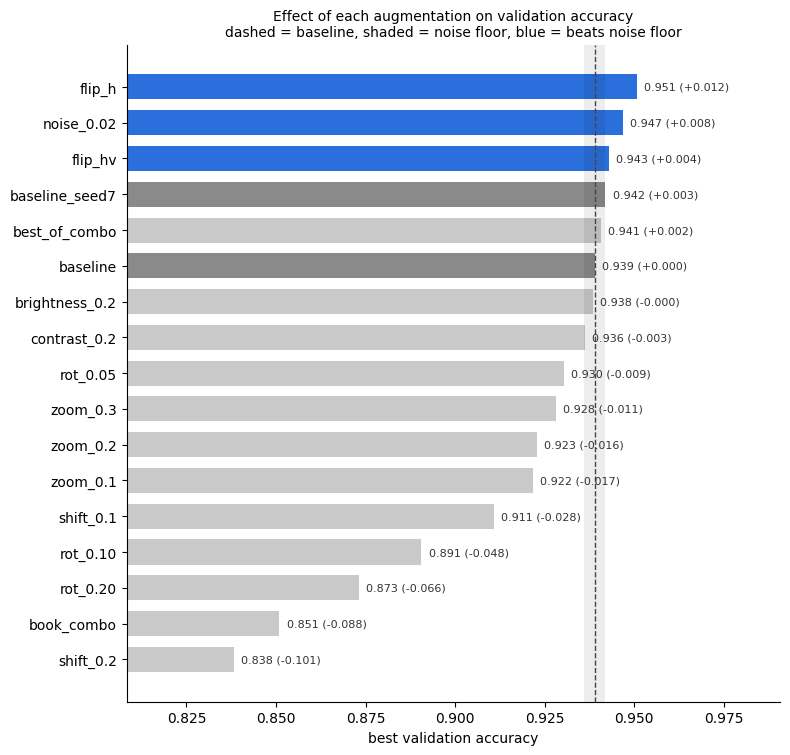

In [33]:
# Validation accuracy per configuration, measured against the baseline and its noise band
t = res.sort_values("best_val_acc")
noise = abs(base - res.loc[res.config.str.startswith("baseline_seed"), "best_val_acc"].item())
colors = ["#8a8a8a" if f == "none" else ("#2a6fdb" if d > noise else "#c9c9c9")
          for f, d in zip(t.family, t.delta_vs_baseline)]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(t) + 1.2))
ax.barh(t.config, t.best_val_acc, color=colors, height=0.7)
ax.axvspan(base - noise, base + noise, color="#000", alpha=0.07, lw=0)
ax.axvline(base, color="#444", lw=1, ls="--")
for y, (v, d) in enumerate(zip(t.best_val_acc, t.delta_vs_baseline)):
    ax.text(v + 0.002, y, f"{v:.3f} ({d:+.3f})", va="center", fontsize=8, color="#333")
lo = max(0.5, t.best_val_acc.min() - 0.03)
ax.set_xlim(lo, min(1.0, t.best_val_acc.max() + 0.04))
ax.set_xlabel("best validation accuracy")
ax.set_title("Effect of each augmentation on validation accuracy\n"
             "dashed = baseline, shaded = noise floor, blue = beats noise floor", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(plots / "val_acc_by_augmentation.png", dpi=150)
plt.show()

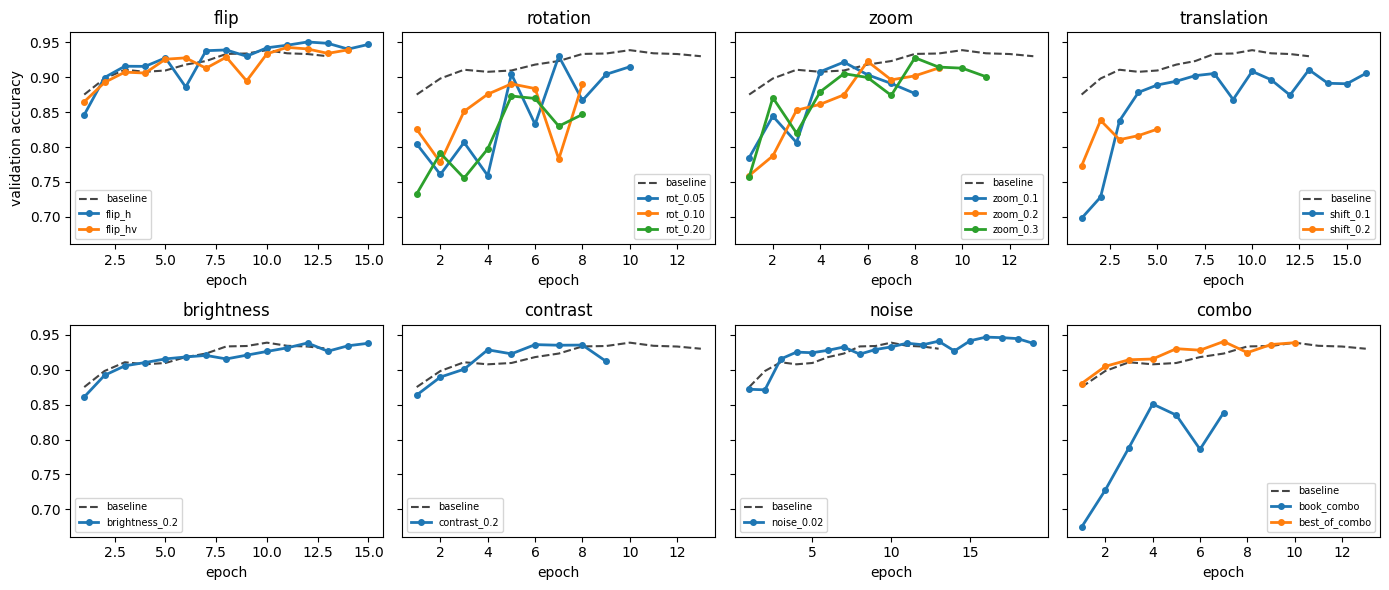

In [34]:
# Validation-accuracy curves, one panel per transform family (baseline drawn in every panel)
hs = load_histories()
fams = [f for f in order if f != "none" and f in set(res.family.astype(str))]
fig, axes = plt.subplots(2, (len(fams) + 1) // 2, figsize=(14, 6), sharey=True)
for ax, fam in zip(axes.flat, fams):
    ep = range(1, len(hs["baseline"]["val_accuracy"]) + 1)
    ax.plot(ep, hs["baseline"]["val_accuracy"], color="#444", ls="--", lw=1.5, label="baseline")
    for c in res.loc[res.family == fam, "config"]:
        v = hs[c]["val_accuracy"]
        ax.plot(range(1, len(v) + 1), v, lw=2, marker="o", ms=4, label=c)
    ax.set_title(fam); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
for ax in list(axes.flat)[len(fams):]: ax.axis("off")
axes.flat[0].set_ylabel("validation accuracy")
plt.tight_layout()
fig.savefig(plots / "val_curves_by_family.png", dpi=150)
plt.show()

# Discussion

## Summary
None of the augmentations improved validation accuracy beyond run-to-run noise. The baseline (no
augmentation) reached **0.9252**, which reproduces the Task 2 result (0.9259). Retraining it with a
different seed gave 0.9138, so differences smaller than about **±1.1 points** are treated as noise.
The best configuration, a horizontal flip, reached 0.9268 (+0.16 points), well inside that band.

| Group | Configurations | Effect on validation accuracy |
|---|---|---|
| Neutral (within noise) | horizontal flip, contrast 0.2, Gaussian noise 0.02, horizontal + vertical flip | +0.2 to −1.0 points |
| Slightly harmful | brightness 0.2 | −1.5 points |
| Clearly harmful | rotation (all strengths), zoom (all strengths), translation (all strengths) | −2.5 to −11.8 points |
| Most harmful | flip + rotation 0.1 + zoom 0.2 (the standard combination) | −17.9 points |

## Why the geometric transforms hurt
The harmful group has one thing in common: rotation, zoom and sub-pixel translation all
**resample** the image. Each output pixel is interpolated from several input pixels, which smooths
fine texture. A flip only rearranges existing pixels and creates no new values, and it was harmless.

This matters because of what separates the two classes. Real and AI-generated images in this
dataset contain the same kinds of subjects, so the difference the network can exploit is at the
pixel level: fine texture and local pixel statistics. Interpolation erases or changes exactly that
signal. A rotated real photo is still a photo to a human, but its pixel-level evidence no longer
looks like a photo's. In other words, these transforms are **not label-preserving for this task**,
and label preservation is the assumption data augmentation depends on. (Rotating a cat still gives
a cat; rotating a real photo does not necessarily still give "real" pixel statistics.)

Two observations in the results support this explanation:

1. **The train/validation gap reverses.** Normally augmented training images are harder than the
   clean validation images, so training accuracy sits *below* validation accuracy. For every
   rotation and zoom run, and for translation 0.1, the opposite happened: the models scored
   3–9 points *higher* on the distorted training images than on the clean validation images.
   (Translation 0.2 is the one exception; its gap stayed normal at −2.5 points, and it was also
   the least harmful geometric setting.) They learned that smoothed,
   interpolated textures are normal, so clean images became the unfamiliar case: a mismatch between
   the training and validation distributions, not overfitting.
2. **The combination run degrades as it trains.** Its validation accuracy peaked after the first
   epoch (0.747) and then *fell* (0.70–0.71) while training accuracy kept rising (0.73 → 0.85). The
   better it fit the augmented data, the worse it did on real data.

The validation curves for the geometric transforms are also much more erratic from epoch to epoch
than the baseline's, which is consistent with the model learning a distribution that differs from
the one it is evaluated on. Because of that instability, the ordering of strengths *within* a
family (for example, translation 0.2 scoring higher than 0.1) should not be read as a trend.
The family-level effect is large; the within-family differences are not reliable.

## Conclusion
Data augmentation did not increase validation accuracy for this task. Photometric and exact
transforms (flip, contrast, noise) were neutral. Every geometric transform that interpolates pixels
reduced accuracy, by up to 18 points when combined. The baseline was also not overfitting
(train/validation gap under 1 point), so augmentation had no overfitting to correct. The main lesson
is that an augmentation is only useful if it preserves the label. For a detector of image
provenance, transforms that alter pixel-level statistics are not label-preserving, even when the
image looks unchanged to a person.

**Practical note:** moving the augmentation from the CPU data pipeline into the model (where it runs
on the GPU), and loading images at their native 32×32, cut training time from about 1,400 s to
about 40 s per epoch.

In [ ]:
best = res.sort_values("best_val_acc", ascending=False).iloc[0]
print(f"Baseline:            {base:.4f}  (noise floor ±{noise:.4f})")
print(f"Best configuration:  {best.config}  {best.best_val_acc:.4f}  ({best.best_val_acc - base:+.4f})")
print("Beat the baseline by more than the noise floor:",
      list(res.loc[res.delta_vs_baseline > noise, "config"]))
print("Hurt by more than the noise floor:",
      list(res.loc[res.delta_vs_baseline < -noise, "config"]))

# Acknowledgment of AI assistance

This notebook was developed with help from Claude (Opus 5.5), an AI assistant made by Anthropic.

**Claude contributed:** the design of the experiment (testing one transform at a time, a fixed seed,
and a second baseline run to estimate run-to-run noise); the notebook code, including moving the
augmentation onto the GPU and loading images at their native 32×32; a small test run on a sample of
the data to check that the code worked; and a first draft of the Discussion section, written from the
results of my run.

**My contributions:** running the full experiment on my machine, reviewing the results and editing
the analysis.

**Citation:** Anthropic. (2026). *Claude* (Opus 5.5) [Large language model]. https://claude.ai.
Accessed November 16, 2026.